# ClusterBP v2: честная переоценка (этап 1 доработки)

Ноутбук заново строит выборку из сырых данных (`2025_04_15/`) и оценивает модели без утечек.
Старые ноутбуки, `cache/` и `data/` не используются и не изменяются: всё промежуточное пишется в `cache_v2/`, итоговые таблицы и графики — в `results_v2/`.

**Что изменено по сравнению с `h0.ipynb` и почему**

| Было в h0 | Стало | Зачем |
|---|---|---|
| Одна цель: смесь кодов 33901, 33900, 33012, 33601, 33801 | Отдельно **A** (33012, 33901, 33902) и **B** (33601, 33801, 33802, 33810, 33911) по просьбе Д.А.; старая цель **OLD** оставлена для сравнения со статьёй | Разные клинические смыслы событий |
| Окна строятся по времени измерения, события — по времени сервера | Всё на шкале времени сервера: в окно истории попадает только то, что было на сервере до отсечки | Причинность |
| Горизонт начинается сразу после отсечки | Для A зазор 1 день, для B — 7 дней | События A подтверждаются врачом в течение ~5 ч после измерения; событие B вычисляется по измерениям прошлой недели, без зазора оно частично определяется входным окном |
| GRU обучается на случайном разбиении окон, без ранней остановки | Все модели обучаются внутри 5-fold CV, разбиение строго по пациентам; ранняя остановка по внутренней валидации | Утечка между пациентами |
| Веса и пороги блендинга подбираются на тесте | Подбираются на внутренней валидации (отдельные пациенты из обучающей части фолда), тест не трогается | Оптимистичная оценка |
| Кластер GDTW по всему ряду пациента, включая будущее | Шаблоны кластеров строятся в каждом фолде по первым 30 дням обучающих пациентов; окно относится к кластеру по своим прошлым 30 дням | Утечка будущего |
| Сбалансированная выборка (~55% положительных) | Оценка при реальной доле событий; F1 на сбалансированном тесте выводится отдельно — только для сопоставления со статьёй | Метрики на сбалансированной выборке клинически не интерпретируются |
| Нет простых базовых правил | Правило «событие уже было за 7 дней», максимальный САД окна, логистическая регрессия | Нужно показать, что модель лучше очевидного |
| t-тест по 5 фолдам | Бутстреп по пациентам с доверительными интервалами для всех метрик и парных разностей | Окна одного пациента коррелированы |

In [1]:
import os
import gc
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, f1_score
import torch

# Константы, определения целей и признаков, фенотипы, модели и метрики — в clusterbp_lib.py.
# CLUSTERBP_DEBUG=1 — быстрый прогон на 1 500 пациентах с выводом в cache_v2_debug/ и results_v2_debug/.
from clusterbp_lib import (DEBUG, RAW_DIR, DATA_DIR, CACHE_DIR, RESULTS_DIR, MODELS_DIR, SEED, TARGETS,
                           EVENT_GROUPS, FEATURE_SETS, LR_COLS, N_FOLDS, N_CLUSTERS, HISTORY_DAYS, STRIDE_DAYS,
                           MIN_HIST_MEAS, MAX_POINTS, FOLLOWUP_DAYS, PHENO_DAYS, fold_masks, fit_phenotypes,
                           assign_phenotypes, set_phenotype_columns, fit_xgb, train_gru, gru_logits, sigmoid,
                           best_threshold, tune_blend, apply_blend, boot_eval, ci, balanced_f1)

warnings.filterwarnings('ignore')
torch.set_num_threads(os.cpu_count())
N_BOOT = 1000
print('DEBUG =', DEBUG)

DEBUG = False


## 1. Загрузка и очистка сырых данных

Очистка как в статье: дубликаты (пациент, время измерения), физиологические границы САД ∈ [40; 250], ДАД ∈ [30; 150], ЧП ∈ [30; 220].
Время переводится в дни (float) по часам сервера.

In [2]:
def to_days(s):
    return pd.to_datetime(s, errors='coerce').values.astype('datetime64[s]').astype('int64') / 86400.0


def parse_int(s):
    return pd.to_numeric(s.astype(str).str.replace(r'\s', '', regex=True), errors='coerce')


def load_raw():
    paths = {k: os.path.join(DATA_DIR, f'{k}.parquet') for k in ['measurements', 'patients', 'events']}
    if all(os.path.exists(p) for p in paths.values()):
        return [pd.read_parquet(paths[k]) for k in ['measurements', 'patients', 'events']]

    cols = {'время измерения': 't_meas', 'время сохранения на сервере': 't', 'САД': 'sbp', 'ДАД': 'dbp',
            'ЧП': 'hr', 'id пациента': 'pid', 'дата рождения пациента': 'birth', 'рост': 'height', 'масса': 'weight'}
    m = pd.read_csv(os.path.join(RAW_DIR, 'Первичные данные от 10.04.2025.csv'),
                    usecols=list(cols), low_memory=False).rename(columns=cols)
    stats = {'raw': len(m)}
    for c in ['sbp', 'dbp', 'hr', 'height', 'weight', 'pid']:
        m[c] = pd.to_numeric(m[c], errors='coerce')
    m['td'] = to_days(m['t'])
    m = m.dropna(subset=['td', 'pid', 'sbp', 'dbp', 'hr'])
    n = len(m)
    m = m.drop_duplicates(subset=['pid', 't_meas'])
    stats['duplicates'] = n - len(m)
    ok = m.sbp.between(40, 250) & m.dbp.between(30, 150) & m.hr.between(30, 220)
    stats['implausible'] = int((~ok).sum())
    m = m[ok]

    pats = m.groupby('pid').agg(birth=('birth', 'first'), height=('height', 'max'), weight=('weight', 'max'))
    pats['birth_days'] = to_days(pats['birth'])
    pats['bmi'] = pats['weight'] / (pats['height'] / 100) ** 2
    pats.loc[~pats['bmi'].between(12, 60), 'bmi'] = np.nan
    grp = pd.read_csv(os.path.join(RAW_DIR, 'МО и Пациенты 10.04.2025.csv'), sep=';')
    grp['pid'] = parse_int(grp['id пациента'])
    grp = grp.dropna(subset=['pid']).drop_duplicates('pid').set_index('pid')['группа наблюдения']
    pats['group'] = grp.reindex(pats.index).fillna('undefined').values
    pats = pats[['birth_days', 'bmi', 'group']].reset_index()

    m = m[['pid', 'td', 'sbp', 'dbp', 'hr']].sort_values(['pid', 'td']).reset_index(drop=True)
    m['pid'] = m['pid'].astype('int64')
    for c in ['sbp', 'dbp', 'hr']:
        m[c] = m[c].astype('float32')

    ev = pd.read_csv(os.path.join(RAW_DIR, 'Клинически значимые события от 15.04.2025.csv'))
    ev.columns = ['prog', 'pid', 'ts', 'code']
    ev['td'] = to_days(ev['ts'])
    ev = ev.dropna(subset=['td', 'pid'])[['pid', 'td', 'code']]
    ev['pid'] = ev['pid'].astype('int64')

    m.to_parquet(paths['measurements'])
    pats.to_parquet(paths['patients'])
    ev.to_parquet(paths['events'])
    json.dump(stats, open(os.path.join(DATA_DIR, 'cleaning_stats.json'), 'w'))
    return m, pats, ev


meas, pats, events = load_raw()
if os.path.exists(os.path.join(DATA_DIR, 'cleaning_stats.json')):
    print('Очистка:', json.load(open(os.path.join(DATA_DIR, 'cleaning_stats.json'))))
if DEBUG:
    rng = np.random.default_rng(SEED)
    keep = rng.choice(meas.pid.unique(), 1500, replace=False)
    meas = meas[meas.pid.isin(keep)].reset_index(drop=True)
print(f'Измерений: {len(meas):,}, пациентов: {meas.pid.nunique():,}, событий: {len(events):,}')

Очистка: {'raw': 4888853, 'duplicates': 78817, 'implausible': 188}
Измерений: 4,809,848, пациентов: 10,937, событий: 1,243,036


## 2. Окна, признаки и цели

Отсечка `t` — полночь по часам сервера, шаг 3 дня. История — измерения, сохранённые на сервере в `[t − 14, t)`.
Цель — есть ли событие нужного типа в `[t + gap, t + gap + 7)`.
Для каждого окна сохраняются:
- табличные признаки (статистики САД/ДАД/ЧП, наклон, вариабельность ARV, доли времени выше порогов, история событий, возраст, ИМТ, группа);
- последовательность последних 20 измерений для GRU (САД, ДАД, ЧП, дни до отсечки, log часов от предыдущего измерения);
- среднесуточный САД за прошлые 30 дней для отнесения к фенотипу.

In [3]:
def prefix(x):
    return np.concatenate([[0.0], np.cumsum(x, dtype=np.float64)])


def build_windows(meas, pats, events):
    paths = [os.path.join(DATA_DIR, f) for f in ['windows.parquet', 'X_seq.npy', 'seq_len.npy',
                                                   'pheno_win.npy', 'pheno_first.npy', 'pheno_first_pid.npy']]
    if not DEBUG and all(os.path.exists(p) for p in paths):
        return (pd.read_parquet(paths[0]), np.load(paths[1]), np.load(paths[2]),
                np.load(paths[3]), np.load(paths[4]), np.load(paths[5]))

    ev_sorted = events.sort_values(['pid', 'td'])
    ev_by_group = {}
    for g, codes in EVENT_GROUPS.items():
        e = ev_sorted if codes is None else ev_sorted[ev_sorted.code.isin(codes)]
        ev_by_group[g] = {pid: grp.values for pid, grp in e.groupby('pid')['td']}
    empty = np.array([], dtype=np.float64)
    pat_static = pats.set_index('pid')

    pid_arr = meas['pid'].values
    bounds = np.flatnonzero(np.diff(pid_arr)) + 1
    starts = np.concatenate([[0], bounds])
    ends = np.concatenate([bounds, [len(pid_arr)]])
    TD, S, D, H = (meas[c].values.astype(np.float64) for c in ['td', 'sbp', 'dbp', 'hr'])

    rows, seqs, lens, pwin, pfirst, pfirst_pid = [], [], [], [], [], []
    t0 = time.time()
    for a, b in zip(starts, ends):
        pid = int(pid_arr[a])
        td, s, d, h = TD[a:b], S[a:b], D[a:b], H[a:b]
        day = np.floor(td)
        first_day, last_day = day[0], day[-1]

        ud, inv = np.unique(day, return_inverse=True)
        daymean = np.bincount(inv, weights=s) / np.bincount(inv)
        off = (ud - first_day).astype(int)
        if (off < PHENO_DAYS).any():
            prof = np.full(PHENO_DAYS, np.nan, dtype=np.float32)
            prof[off[off < PHENO_DAYS]] = daymean[off < PHENO_DAYS]
            pfirst.append(prof)
            pfirst_pid.append(pid)

        cut = np.arange(first_day + HISTORY_DAYS, last_day - FOLLOWUP_DAYS + 1 + 1e-9, STRIDE_DAYS)
        if len(cut) == 0:
            continue
        lo = np.searchsorted(td, cut - HISTORY_DAYS)
        hi = np.searchsorted(td, cut)
        n = hi - lo
        ok = n >= MIN_HIST_MEAS
        if not ok.any():
            continue
        cut, lo, hi, n = cut[ok], lo[ok], hi[ok], n[ok]

        u = td - first_day
        pp = s - d
        f = {'pid': np.full(len(cut), pid), 'cut': cut}
        for name, x in [('sbp', s), ('dbp', d), ('hr', h), ('pp', pp)]:
            P, P2 = prefix(x), prefix(x * x)
            mean = (P[hi] - P[lo]) / n
            var = np.maximum((P2[hi] - P2[lo]) / n - mean ** 2, 0) * n / np.maximum(n - 1, 1)
            f[f'{name}_mean'] = mean
            f[f'{name}_std'] = np.sqrt(var)
            if name == 'pp':
                continue
            f[f'{name}_last'] = x[hi - 1]
            Pu, Puu, Pux = prefix(u), prefix(u * u), prefix(u * x)
            su, suu, sux, sx = Pu[hi] - Pu[lo], Puu[hi] - Puu[lo], Pux[hi] - Pux[lo], P[hi] - P[lo]
            den = n * suu - su ** 2
            f[f'{name}_slope'] = np.where(den > 1e-9, (n * sux - su * sx) / np.where(den > 1e-9, den, 1), np.nan)
            PA = prefix(np.concatenate([[0.0], np.abs(np.diff(x))]))
            f[f'{name}_arv'] = (PA[hi] - PA[lo + 1]) / np.maximum(n - 1, 1)
        for name, x in [('tir140', s >= 140), ('frac160', s >= 160), ('frac180', s >= 180), ('dbp_frac90', d >= 90)]:
            P = prefix(x.astype(float))
            f[name] = (P[hi] - P[lo]) / n
        P = prefix(s)
        lo3 = np.searchsorted(td, cut - 3)
        with np.errstate(invalid='ignore', divide='ignore'):
            f['sbp_last3d_minus_prev'] = (P[hi] - P[lo3]) / (hi - lo3) - (P[lo3] - P[lo]) / (lo3 - lo)
        f['sbp_last3d_minus_prev'] = np.where((hi > lo3) & (lo3 > lo), f['sbp_last3d_minus_prev'], np.nan)
        newday = prefix(np.concatenate([[0.0], (np.diff(day) > 0).astype(float)]))
        f['n_meas'] = n
        f['n_days'] = 1 + newday[hi] - newday[lo + 1]
        f['days_since_last_meas'] = cut - td[hi - 1]
        f['days_in_program'] = cut - first_day
        st = pat_static.loc[pid]
        f['age'] = (cut - st['birth_days']) / 365.25
        f['bmi'] = np.full(len(cut), st['bmi'])
        f['grp_experience'] = np.full(len(cut), float(st['group'] == 'experience'))
        f['grp_control'] = np.full(len(cut), float(str(st['group']).startswith('control')))
        mn = np.empty(len(cut)); mx = np.empty(len(cut))
        dmn = np.empty(len(cut)); dmx = np.empty(len(cut))
        hmn = np.empty(len(cut)); hmx = np.empty(len(cut))
        seq = np.zeros((len(cut), MAX_POINTS, 5), dtype=np.float32)
        pw = np.full((len(cut), PHENO_DAYS), np.nan, dtype=np.float32)
        gap_h = np.log1p(np.concatenate([[0.0], np.diff(td) * 24]))
        for i in range(len(cut)):
            sl = slice(lo[i], hi[i])
            mn[i], mx[i] = s[sl].min(), s[sl].max()
            dmn[i], dmx[i] = d[sl].min(), d[sl].max()
            hmn[i], hmx[i] = h[sl].min(), h[sl].max()
            k = min(n[i], MAX_POINTS)
            q = slice(hi[i] - k, hi[i])
            seq[i, MAX_POINTS - k:, 0] = s[q]
            seq[i, MAX_POINTS - k:, 1] = d[q]
            seq[i, MAX_POINTS - k:, 2] = h[q]
            seq[i, MAX_POINTS - k:, 3] = cut[i] - td[q]
            seq[i, MAX_POINTS - k:, 4] = gap_h[q]
            if hi[i] - k == 0:
                seq[i, MAX_POINTS - k, 4] = 0
            j0, j1 = np.searchsorted(ud, cut[i] - PHENO_DAYS), np.searchsorted(ud, cut[i])
            pw[i, (ud[j0:j1] - (cut[i] - PHENO_DAYS)).astype(int)] = daymean[j0:j1]
        f.update(sbp_min=mn, sbp_max=mx, dbp_min=dmn, dbp_max=dmx, hr_min=hmn, hr_max=hmx)

        for g in EVENT_GROUPS:
            e = ev_by_group[g].get(pid, empty)
            i_cut = np.searchsorted(e, cut)
            f[f'ev_{g}_14'] = i_cut - np.searchsorted(e, cut - 14)
            f[f'ev_{g}_7'] = i_cut - np.searchsorted(e, cut - 7)
            last = np.where(i_cut > 0, e[np.maximum(i_cut - 1, 0)] if len(e) else 0, np.nan)
            f[f'ev_{g}_days_since'] = np.where(i_cut > 0, cut - last, np.nan)
        for name, cfg in TARGETS.items():
            e = ev_by_group[name].get(pid, empty)
            a0 = cut + cfg['gap']
            f[f'y_{name}'] = (np.searchsorted(e, a0 + cfg['horizon']) - np.searchsorted(e, a0) > 0).astype(np.int8)

        rows.append(pd.DataFrame(f))
        seqs.append(seq)
        lens.append(np.minimum(n, MAX_POINTS).astype(np.int8))
        pwin.append(pw)
    print(f'Окна построены за {time.time() - t0:.0f} с')

    win = pd.concat(rows, ignore_index=True)
    X_seq = np.concatenate(seqs)
    seq_len = np.concatenate(lens)
    pheno_win = np.concatenate(pwin)
    pheno_first = np.stack(pfirst)
    pheno_first_pid = np.array(pfirst_pid)
    if not DEBUG:
        win.to_parquet(paths[0])
        for p, arr in zip(paths[1:], [X_seq, seq_len, pheno_win, pheno_first, pheno_first_pid]):
            np.save(p, arr)
    return win, X_seq, seq_len, pheno_win, pheno_first, pheno_first_pid


win, X_seq, seq_len, pheno_win, pheno_first, pheno_first_pid = build_windows(meas, pats, events)
print(f'Окон: {len(win):,}, пациентов: {win.pid.nunique():,}')
summary = pd.DataFrame({
    'доля положительных окон': {n: win[f'y_{n}'].mean() for n in TARGETS},
    'пациентов с ≥1 положительным окном': {n: win.groupby('pid')[f'y_{n}'].max().sum() for n in TARGETS},
})
summary

Окон: 420,355, пациентов: 9,413


,доля положительных окон,пациентов с ≥1 положительным окном
A,0.046573,2355
B,0.130675,4161
OLD,0.040387,2051
A_bp,0.037882,1855
B_no33810,0.121935,3414
B_gap0,0.131246,4139


## 3. Фенотипы GDTW без утечки

В каждом фолде:
1. берутся обучающие пациенты, у которых первые 30 дней наблюдения покрыты измерениями (есть день 0 и день ≥ 25, не меньше 15 дней с данными);
2. их z-нормированные среднесуточные ряды САД кластеризуются GDTW (γ = 1, окно 14 дней) + Ward, k = 3, как в статье;
3. шаблон кластера — медианный z-профиль;
4. каждое окно относится к ближайшему шаблону по своим **прошлым** 30 дням (1-NN по GDTW).

Время в GDTW считается от начала ряда, а не по календарю: в старой реализации отсчёт шёл от общей минимальной даты, из-за чего ряды разных пациентов сравнивались по календарным датам.
Кластеры упорядочены по средней вариабельности САД участников: кластер 0 — самый вариабельный.
Реализация — `fit_phenotypes` и `assign_phenotypes` в `clusterbp_lib.py`.

## 4. Модели

- **Правила:** `rule_persist` — число событий того же типа за последние 7 дней; `rule_maxSBP` — максимальный САД окна.
- **LR:** логистическая регрессия на полном наборе признаков.
- **XGB_paper6:** XGBoost на 6 признаках статьи (средний САД, SD САД, TIR, возраст, ИМТ, кластер); **XGB_bp:** все признаки АД без истории событий; **XGB_full:** плюс история событий.
- **GRU:** GRU(64) + аддитивное внимание по последним 20 измерениям (как описано в статье), ранняя остановка по AUPRC на внутренней валидации. При обучении отрицательные окна прорежены до 3:1, вероятности потом пересчитываются к реальной доле событий.
- **Смеси:** `Blend_simple` (w = 0.5), `Blend_global` (w и порог подбираются на валидации) и `ClusterBP` (w и порог по кластерам) — в двух вариантах: с XGB_paper6, как в статье, и с XGB_full (`*_full`).

Порог каждой модели подбирается на внутренней валидации по Macro F1 (как в статье) и затем применяется к тесту.
Реализация моделей, подбора порога и весов смеси — в `clusterbp_lib.py`.

## 5. Кросс-валидация

5 фолдов по пациентам (одинаковые для всех целей). Внутри обучающей части фолда 20% пациентов уходят во внутреннюю валидацию: на ней работают ранняя остановка, подбор порогов и весов смеси. Тестовые пациенты используются только для итоговых предсказаний.

In [4]:
patients = win['pid'].values
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = np.full(len(win), -1)
for k, (_, te) in enumerate(sgkf.split(win, win['y_A'], groups=patients)):
    folds[te] = k
win['fold'] = folds

oof = {name: {} for name in TARGETS}          # предсказания на тесте: модель -> (score, pred)
fold_metrics, blend_params, cluster_info, gru_logs = [], [], [], []
t_all = time.time()

# Если кросс-валидация уже посчитана, берём готовые предсказания из кеша
OOF_PATH = os.path.join(CACHE_DIR, 'oof_predictions.parquet')
RESUME = not DEBUG and os.path.exists(OOF_PATH) and os.path.exists(os.path.join(RESULTS_DIR, 'fold_metrics.csv'))
if RESUME:
    oof_df = pd.read_parquet(OOF_PATH)
    for col in oof_df.columns:
        if col.endswith('__score'):
            name, model_name, _ = col.split('__')
            oof[name][model_name] = (oof_df[col].values, oof_df[f'{name}__{model_name}__pred'].values)
    fold_metrics = pd.read_csv(os.path.join(RESULTS_DIR, 'fold_metrics.csv')).to_dict('records')
    blend_params = pd.read_csv(os.path.join(RESULTS_DIR, 'clusterbp_params.csv')).to_dict('records')
    cluster_info = pd.read_csv(os.path.join(RESULTS_DIR, 'clusters.csv')).to_dict('records')
    print('Кросс-валидация загружена из кеша')

for k in ([] if RESUME else range(N_FOLDS)):
    t_fold = time.time()
    tr, va, te = fold_masks(win, k)
    train_pids = np.unique(patients[~te])

    templates, sizes, vol = fit_phenotypes(pheno_first, pheno_first_pid, train_pids, SEED + k)
    cl, dist = assign_phenotypes(pheno_win, templates)
    set_phenotype_columns(win, cl, dist)
    np.save(os.path.join(MODELS_DIR, f'templates_fold{k}.npy'), templates)
    for c in range(N_CLUSTERS):
        row = {'fold': k, 'cluster': c, 'n_clustered_patients': int(sizes[c]), 'volatility': vol[c],
               'share_train_windows': float((cl[tr] == c).mean())}
        for name in TARGETS:
            row[f'event_rate_{name}'] = float(win.loc[tr & (cl == c), f'y_{name}'].mean())
        cluster_info.append(row)

    for name, cfg in TARGETS.items():
        y = win[f'y_{name}'].values
        ytr, yva, yte = y[tr], y[va], y[te]
        res = {}

        res['rule_persist'] = (win[f'ev_{name}_7'].values.astype(float), None)
        res['rule_maxSBP'] = (win['sbp_max'].values, None)

        lr = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=3000))
        lr.fit(win.loc[tr, LR_COLS].values, ytr)
        res['LR'] = (lr.predict_proba(win[LR_COLS].values)[:, 1], None)

        xgb_sets = ['full'] if not cfg['full'] else ['paper6', 'bp', 'full']
        for fs in xgb_sets:
            cols = FEATURE_SETS[fs]
            m = fit_xgb(win.loc[tr, cols].values, ytr, win.loc[va, cols].values, yva, SEED + k)
            res[f'XGB_{fs}'] = (m.predict_proba(win[cols].values)[:, 1], None)
            m.save_model(os.path.join(MODELS_DIR, f'xgb_{fs}_{name}_fold{k}.json'))

        if cfg['full']:
            model, mu, sd, corr, log = train_gru(X_seq[tr], seq_len[tr], ytr, X_seq[va], seq_len[va], yva, SEED + k)
            gru_logs.append({'target': name, 'fold': k, 'epochs': len(log), 'val_auprc': log})
            torch.save({'state': model.state_dict(), 'mu': mu, 'sd': sd, 'corr': corr},
                       os.path.join(MODELS_DIR, f'gru_{name}_fold{k}.pt'))
            pg = sigmoid(gru_logits(model, X_seq, seq_len, mu, sd) + corr)
            res['GRU'] = (pg, None)
            for suffix, xname in [('', 'XGB_paper6'), ('_full', 'XGB_full')]:
                px = res[xname][0]
                simple = 0.5 * pg + 0.5 * px
                thr, _ = best_threshold(yva, simple[va])
                res[f'Blend_simple{suffix}'] = (simple, (simple > thr).astype(np.int8))
                gp = tune_blend(yva, pg[va], px[va])
                res[f'Blend_global{suffix}'] = apply_blend(pg, px, gp)
                cp = tune_blend(yva, pg[va], px[va], clusters=cl[va])
                res[f'ClusterBP{suffix}'] = apply_blend(pg, px, cp, clusters=cl)
                for key, (w, thr) in cp.items():
                    blend_params.append({'target': name, 'fold': k, 'variant': 'ClusterBP' + suffix,
                                         'cluster': key, 'w_gru': w, 'threshold': thr})

        for model_name, (score, pred) in res.items():
            if pred is None:
                thr, _ = best_threshold(yva, score[va])
                pred = (score > thr).astype(np.int8)
            st = oof[name].setdefault(model_name, (np.full(len(win), np.nan), np.zeros(len(win), np.int8)))
            st[0][te] = score[te]
            st[1][te] = pred[te]
            fold_metrics.append({'target': name, 'fold': k, 'model': model_name,
                                 'auroc': roc_auc_score(yte, score[te]),
                                 'auprc': average_precision_score(yte, score[te]),
                                 'macro_f1': f1_score(yte, pred[te], average='macro')})
    print(f'Фолд {k}: {time.time() - t_fold:.0f} с')
    gc.collect()

print(f'Всего: {(time.time() - t_all) / 60:.1f} мин')
fold_df = pd.DataFrame(fold_metrics)
if not RESUME:
    fold_df.to_csv(os.path.join(RESULTS_DIR, 'fold_metrics.csv'), index=False)
    pd.DataFrame(blend_params).to_csv(os.path.join(RESULTS_DIR, 'clusterbp_params.csv'), index=False)
    pd.DataFrame(cluster_info).to_csv(os.path.join(RESULTS_DIR, 'clusters.csv'), index=False)
    json.dump(gru_logs, open(os.path.join(RESULTS_DIR, 'gru_training.json'), 'w'))

    oof_df = win[['pid', 'cut', 'fold'] + [f'y_{n}' for n in TARGETS]].copy()
    for name in TARGETS:
        for model_name, (score, pred) in oof[name].items():
            oof_df[f'{name}__{model_name}__score'] = score
            oof_df[f'{name}__{model_name}__pred'] = pred
    oof_df.to_parquet(OOF_PATH)

Кросс-валидация загружена из кеша
Всего: 0.0 мин


## 6. Итоговые метрики с доверительными интервалами

Предсказания всех фолдов объединены (out-of-fold). 95% ДИ — бутстреп по пациентам (пациент выбирается целиком со всеми окнами).
`macro_F1_balanced` — Macro F1 на тесте, где отрицательные окна случайно прорежены до числа положительных, а порог подобран на такой же сбалансированной выборке **других** фолдов. Это условия статьи (тест с ~57% положительных), поэтому колонка нужна **только** для сопоставления с таблицей 4; клинического смысла у неё нет.

In [5]:
COMPARISONS = [('ClusterBP', 'Blend_global'), ('ClusterBP', 'Blend_simple'), ('ClusterBP', 'GRU'),
               ('ClusterBP', 'XGB_paper6'), ('ClusterBP_full', 'Blend_global_full'), ('ClusterBP_full', 'XGB_full'),
               ('XGB_full', 'XGB_bp'), ('XGB_full', 'rule_persist'), ('XGB_bp', 'rule_maxSBP'), ('GRU', 'rule_maxSBP')]

all_tables, all_comp = {}, []
rng = np.random.default_rng(SEED)
for name in TARGETS:
    y = oof_df[f'y_{name}'].values.astype(float)
    pid = oof_df['pid'].values
    names = list(oof[name])
    models = [(oof_df[f'{name}__{m}__score'].values, oof_df[f'{name}__{m}__pred'].values.astype(float)) for m in names]
    t0 = time.time()
    boot_path = os.path.join(CACHE_DIR, f'bootstrap_{name}.npy')
    if not DEBUG and os.path.exists(boot_path):
        B = np.load(boot_path)
    else:
        B = boot_eval(y, pid, models)
        if not DEBUG:
            np.save(boot_path, B)
    pos_idx = np.flatnonzero(y == 1)
    bal = np.sort(np.concatenate([pos_idx, rng.choice(np.flatnonzero(y == 0), len(pos_idx), replace=False)]))
    fold = oof_df['fold'].values
    rows = []
    for j, m in enumerate(names):
        score, pred = models[j]
        fd = fold_df[(fold_df.target == name) & (fold_df.model == m)]
        tp = ((pred == 1) & (y == 1)).sum(); fp = ((pred == 1) & (y == 0)).sum()
        fn = ((pred == 0) & (y == 1)).sum(); tn = ((pred == 0) & (y == 0)).sum()
        is_prob = not m.startswith('rule')
        rows.append({
            'model': m,
            'AUROC': roc_auc_score(y, score), 'AUROC 95% ДИ': ci(B[:, j, 0]),
            'AUPRC': average_precision_score(y, score), 'AUPRC 95% ДИ': ci(B[:, j, 1]),
            'Brier': brier_score_loss(y, np.clip(score, 0, 1)) if is_prob else np.nan,
            'macro_F1': f1_score(y, pred, average='macro'), 'macro_F1 95% ДИ': ci(B[:, j, 2]),
            'macro_F1 по фолдам': f'{fd.macro_f1.mean():.3f} ± {fd.macro_f1.std():.3f}',
            'sensitivity': tp / (tp + fn), 'specificity': tn / (tn + fp), 'PPV': tp / max(tp + fp, 1),
            'macro_F1_balanced': '{:.3f} ± {:.3f}'.format(*balanced_f1(y, score, fold, bal)),
        })
    table = pd.DataFrame(rows).set_index('model').sort_values('AUPRC', ascending=False)
    all_tables[name] = table
    table.to_csv(os.path.join(RESULTS_DIR, f'metrics_{name}.csv'))
    for a, b in COMPARISONS:
        if a in names and b in names:
            ia, ib = names.index(a), names.index(b)
            for mi, metric in enumerate(['AUROC', 'AUPRC', 'macro_F1']):
                d = B[:, ia, mi] - B[:, ib, mi]
                point = table.loc[a, metric] - table.loc[b, metric]
                all_comp.append({'target': name, 'comparison': f'{a} − {b}', 'metric': metric,
                                 'delta': point, '95% ДИ': ci(d),
                                 'p (двусторонний)': min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))})
    print(f'{name}: бутстреп {time.time() - t0:.0f} с')

comp_df = pd.DataFrame(all_comp)
comp_df.to_csv(os.path.join(RESULTS_DIR, 'comparisons.csv'), index=False)

A: бутстреп 3 с


B: бутстреп 4 с


OLD: бутстреп 3 с


A_bp: бутстреп 1 с


B_no33810: бутстреп 1 с


B_gap0: бутстреп 1 с


In [6]:
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
for name, table in all_tables.items():
    print(f"\n=== {TARGETS[name]['title']} — доля положительных {oof_df[f'y_{name}'].mean():.3f} ===")
    display(table.round(3))


=== A: острый подъём (красные зоны) — доля положительных 0.047 ===


,AUROC,AUROC 95% ДИ,AUPRC,AUPRC 95% ДИ,Brier,macro_F1,macro_F1 95% ДИ,macro_F1 по фолдам,sensitivity,specificity,PPV,macro_F1_balanced
model,,,,,,,,,,,,
Blend_global_full,0.896,[0.890; 0.902],0.449,[0.420; 0.476],0.033,0.715,[0.704; 0.725],0.714 ± 0.017,0.463,0.972,0.451,0.816 ± 0.013
ClusterBP_full,0.896,[0.890; 0.902],0.449,[0.420; 0.476],0.033,0.714,[0.704; 0.724],0.714 ± 0.016,0.470,0.971,0.442,0.816 ± 0.011
XGB_full,0.896,[0.890; 0.902],0.448,[0.419; 0.474],0.033,0.714,[0.704; 0.723],0.714 ± 0.016,0.461,0.972,0.449,0.820 ± 0.010
Blend_simple_full,0.894,[0.888; 0.900],0.445,[0.416; 0.472],0.033,0.715,[0.705; 0.725],0.714 ± 0.017,0.467,0.972,0.447,0.814 ± 0.012
XGB_bp,0.887,[0.880; 0.893],0.431,[0.403; 0.457],0.034,0.710,[0.700; 0.720],0.711 ± 0.015,0.463,0.971,0.436,0.811 ± 0.010
LR,0.874,[0.866; 0.881],0.418,[0.388; 0.445],0.034,0.706,[0.695; 0.717],0.705 ± 0.019,0.434,0.973,0.444,0.803 ± 0.012
ClusterBP,0.876,[0.868; 0.883],0.406,[0.376; 0.432],0.034,0.703,[0.692; 0.713],0.703 ± 0.017,0.441,0.971,0.428,0.799 ± 0.015
Blend_global,0.875,[0.868; 0.882],0.405,[0.375; 0.431],0.034,0.703,[0.692; 0.713],0.702 ± 0.020,0.436,0.972,0.432,0.797 ± 0.016
GRU,0.872,[0.865; 0.879],0.403,[0.374; 0.430],0.034,0.701,[0.690; 0.711],0.700 ± 0.018,0.439,0.971,0.423,0.794 ± 0.015



=== B: превышение целевого АД (через неделю) — доля положительных 0.131 ===


,AUROC,AUROC 95% ДИ,AUPRC,AUPRC 95% ДИ,Brier,macro_F1,macro_F1 95% ДИ,macro_F1 по фолдам,sensitivity,specificity,PPV,macro_F1_balanced
model,,,,,,,,,,,,
Blend_global_full,0.910,[0.906; 0.914],0.677,[0.660; 0.693],0.067,0.784,[0.777; 0.791],0.784 ± 0.004,0.615,0.946,0.632,0.830 ± 0.003
ClusterBP_full,0.910,[0.906; 0.914],0.677,[0.660; 0.692],0.067,0.784,[0.777; 0.791],0.784 ± 0.004,0.620,0.945,0.628,0.831 ± 0.003
XGB_full,0.910,[0.906; 0.914],0.676,[0.658; 0.691],0.067,0.784,[0.777; 0.791],0.784 ± 0.004,0.621,0.944,0.626,0.830 ± 0.003
Blend_simple_full,0.908,[0.904; 0.912],0.673,[0.657; 0.689],0.068,0.784,[0.777; 0.791],0.784 ± 0.004,0.619,0.945,0.628,0.828 ± 0.004
XGB_bp,0.905,[0.901; 0.909],0.664,[0.647; 0.681],0.068,0.780,[0.773; 0.787],0.780 ± 0.004,0.608,0.945,0.626,0.825 ± 0.004
GRU,0.895,[0.890; 0.899],0.643,[0.626; 0.660],0.071,0.773,[0.766; 0.780],0.773 ± 0.004,0.592,0.945,0.618,0.815 ± 0.005
ClusterBP,0.895,[0.890; 0.899],0.643,[0.626; 0.660],0.071,0.776,[0.769; 0.783],0.776 ± 0.004,0.608,0.943,0.614,0.818 ± 0.006
Blend_global,0.895,[0.890; 0.899],0.641,[0.624; 0.658],0.071,0.775,[0.769; 0.782],0.775 ± 0.004,0.595,0.945,0.622,0.817 ± 0.006
LR,0.895,[0.890; 0.899],0.631,[0.614; 0.649],0.072,0.774,[0.767; 0.781],0.774 ± 0.004,0.597,0.944,0.614,0.815 ± 0.003



=== OLD: цель из первой версии статьи — доля положительных 0.040 ===


...

,AUROC,AUROC 95% ДИ,AUPRC,AUPRC 95% ДИ,Brier,macro_F1,macro_F1 95% ДИ,macro_F1 по фолдам,sensitivity,specificity,PPV,macro_F1_balanced
model,,,,,,,,,,,,
XGB_full,0.923,[0.918; 0.928],0.473,[0.442; 0.501],0.026,0.729,[0.718; 0.739],0.728 ± 0.011,0.501,0.977,0.460,0.852 ± 0.003
LR,0.913,[0.907; 0.918],0.445,[0.415; 0.473],0.027,0.719,[0.709; 0.730],0.718 ± 0.014,0.464,0.978,0.457,0.843 ± 0.006
rule_maxSBP,0.892,[0.885; 0.898],0.312,[0.285; 0.340],NaN,0.677,[0.667; 0.688],0.677 ± 0.010,0.463,0.963,0.328,0.821 ± 0.005
rule_persist,0.706,[0.694; 0.717],0.279,[0.252; 0.306],NaN,0.698,[0.687; 0.709],0.698 ± 0.013,0.433,0.975,0.406,0.681 ± 0.016



=== B без 33810 (признаки достижения ЦУ) — доля положительных 0.122 ===


,AUROC,AUROC 95% ДИ,AUPRC,AUPRC 95% ДИ,Brier,macro_F1,macro_F1 95% ДИ,macro_F1 по фолдам,sensitivity,specificity,PPV,macro_F1_balanced
model,,,,,,,,,,,,
XGB_full,0.932,[0.929; 0.936],0.699,[0.681; 0.715],0.060,0.796,[0.789; 0.803],0.796 ± 0.005,0.660,0.945,0.625,0.855 ± 0.002
LR,0.917,[0.913; 0.921],0.649,[0.631; 0.667],0.064,0.784,[0.777; 0.791],0.784 ± 0.004,0.636,0.943,0.608,0.839 ± 0.002
rule_persist,0.787,[0.779; 0.794],0.491,[0.473; 0.509],NaN,0.774,[0.767; 0.781],0.774 ± 0.005,0.611,0.943,0.596,0.774 ± 0.007
rule_maxSBP,0.787,[0.778; 0.795],0.352,[0.334; 0.371],NaN,0.660,[0.652; 0.669],0.660 ± 0.008,0.441,0.901,0.383,0.715 ± 0.009



=== B без зазора — доля положительных 0.131 ===


,AUROC,AUROC 95% ДИ,AUPRC,AUPRC 95% ДИ,Brier,macro_F1,macro_F1 95% ДИ,macro_F1 по фолдам,sensitivity,specificity,PPV,macro_F1_balanced
model,,,,,,,,,,,,
XGB_full,0.947,[0.944; 0.949],0.824,[0.815; 0.834],0.048,0.849,[0.844; 0.853],0.849 ± 0.001,0.680,0.974,0.797,0.873 ± 0.001
LR,0.930,[0.927; 0.933],0.769,[0.757; 0.781],0.055,0.833,[0.828; 0.838],0.833 ± 0.003,0.669,0.966,0.749,0.857 ± 0.002
rule_persist,0.824,[0.819; 0.830],0.609,[0.595; 0.624],NaN,0.814,[0.808; 0.820],0.814 ± 0.003,0.660,0.956,0.692,0.813 ± 0.004
rule_maxSBP,0.796,[0.788; 0.804],0.395,[0.376; 0.414],NaN,0.676,[0.668; 0.683],0.676 ± 0.006,0.452,0.908,0.427,0.722 ± 0.010


In [7]:
display(comp_df[comp_df.metric != 'AUROC'].round(4))

,target,comparison,metric,delta,95% ДИ,p (двусторонний)
1,A,ClusterBP − Blend_global,AUPRC,0.0010,[-0.001; 0.003],0.210
2,A,ClusterBP − Blend_global,macro_F1,0.0001,[-0.002; 0.002],0.800
4,A,ClusterBP − Blend_simple,AUPRC,0.0030,[-0.000; 0.006],0.066
5,A,ClusterBP − Blend_simple,macro_F1,0.0018,[-0.000; 0.004],0.072
7,A,ClusterBP − GRU,AUPRC,0.0029,[0.000; 0.006],0.048
...,...,...,...,...,...,...
92,A_bp,XGB_full − rule_persist,macro_F1,0.0309,[0.027; 0.035],0.000
94,B_no33810,XGB_full − rule_persist,AUPRC,0.2080,[0.202; 0.213],0.000
95,B_no33810,XGB_full − rule_persist,macro_F1,0.0216,[0.020; 0.024],0.000
97,B_gap0,XGB_full − rule_persist,AUPRC,0.2156,[0.210; 0.222],0.000


## 7. Параметры ClusterBP и кластеры по фолдам

Аналог таблицы 2 статьи, но параметры подобраны на валидации каждого фолда, а не на тесте.

In [8]:
bp_df = pd.DataFrame(blend_params)
bp_df = bp_df[bp_df.cluster != 'global']
display(bp_df.groupby(['target', 'variant', 'cluster'])[['w_gru', 'threshold']].agg(['mean', 'std']).round(3))
cl_df = pd.DataFrame(cluster_info)
display(cl_df.groupby('cluster').mean(numeric_only=True).drop(columns='fold').round(3))

w_gru        threshold       
                               mean    std      mean    std
target variant        cluster                              
A      ClusterBP      0        0.79  0.156     0.177  0.015
                      1        0.69  0.119     0.206  0.028
                      2        0.69  0.175     0.247  0.053
       ClusterBP_full 0        0.34  0.263     0.211  0.030
                      1        0.30  0.071     0.221  0.035
                      2        0.27  0.076     0.244  0.025
B      ClusterBP      0        0.82  0.120     0.265  0.036
                      1        0.74  0.055     0.312  0.045
                      2        0.75  0.071     0.354  0.038
       ClusterBP_full 0        0.20  0.173     0.326  0.021
                      1        0.37  0.135     0.330  0.037
                      2        0.14  0.065     0.349  0.021
OLD    ClusterBP      0        0.81  0.147     0.224  0.053
                      1        0.72  0.182     0.241  0.041
                      2        0.59  0.198     0.241  0.033
       ClusterBP_full 0        0.15  0.146     0.254  0.033
                      1        0.24  0.114     0.239  0.041
                      2        0.17  0.057     0.280  0.022

,n_clustered_patients,volatility,share_train_windows,event_rate_A,event_rate_B,event_rate_OLD,event_rate_A_bp,event_rate_B_no33810,event_rate_B_gap0
cluster,,,,,,,,,
0,334.8,9.365,0.190,0.040,0.120,0.033,0.032,0.112,0.111
1,671.8,8.950,0.382,0.044,0.126,0.036,0.035,0.117,0.119
2,493.4,8.620,0.428,0.051,0.138,0.046,0.042,0.129,0.148


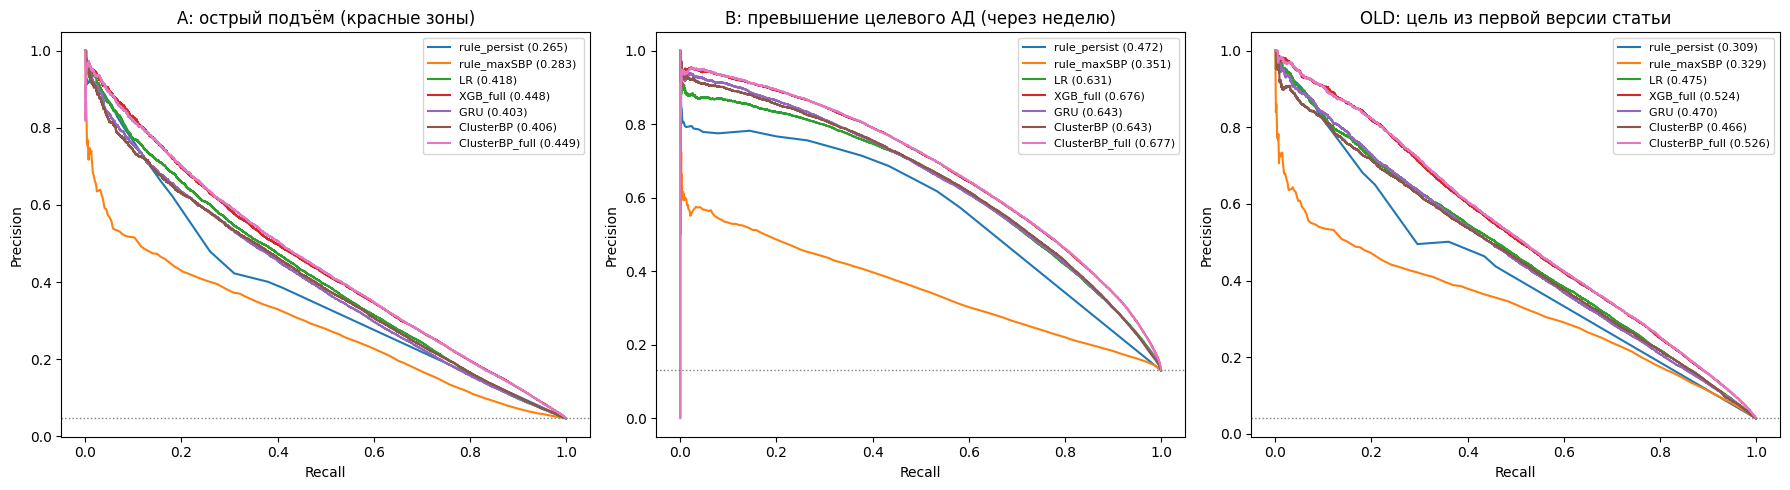

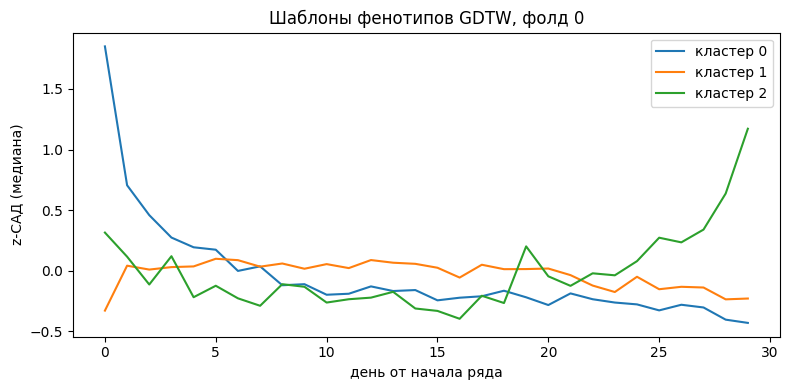

In [9]:
from sklearn.metrics import precision_recall_curve

show = ['rule_persist', 'rule_maxSBP', 'LR', 'XGB_full', 'GRU', 'ClusterBP', 'ClusterBP_full']
full_targets = [n for n, c in TARGETS.items() if c['full']]
fig, axes = plt.subplots(1, len(full_targets), figsize=(6 * len(full_targets), 5))
for ax, name in zip(np.atleast_1d(axes), full_targets):
    y = oof_df[f'y_{name}'].values
    for m in show:
        if m in oof[name]:
            p, r, _ = precision_recall_curve(y, oof_df[f'{name}__{m}__score'].values)
            ax.plot(r, p, label=f"{m} ({all_tables[name].loc[m, 'AUPRC']:.3f})")
    ax.axhline(y.mean(), color='gray', ls=':', lw=1)
    ax.set_title(TARGETS[name]['title'])
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'pr_curves.png'), dpi=200, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
T0 = np.load(os.path.join(MODELS_DIR, 'templates_fold0.npy'))
for c, prof in enumerate(T0):
    ax.plot(np.arange(PHENO_DAYS), prof, label=f'кластер {c}')
ax.set_xlabel('день от начала ряда')
ax.set_ylabel('z-САД (медиана)')
ax.set_title('Шаблоны фенотипов GDTW, фолд 0')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'phenotype_templates_fold0.png'), dpi=200, bbox_inches='tight')
plt.show()